Dataset Loaded Successfully!
Features: (442, 10)
Target: (442, 1)
Training Samples: 331
Testing Samples: 111

Bias: [0.00893719]

Coefficients:
 [[ 0.03589409]
 [-0.14674966]
 [ 0.31870012]
 [ 0.23189938]
 [-0.46524715]
 [ 0.22114379]
 [ 0.01825949]
 [ 0.15267531]
 [ 0.38730569]
 [ 0.02674186]]

===== MODEL PERFORMANCE =====
MAE: 41.64289024081671
MSE: 2868.0464120273327
RMSE: 53.554144676461156
R2 Score: 0.48133683500412505


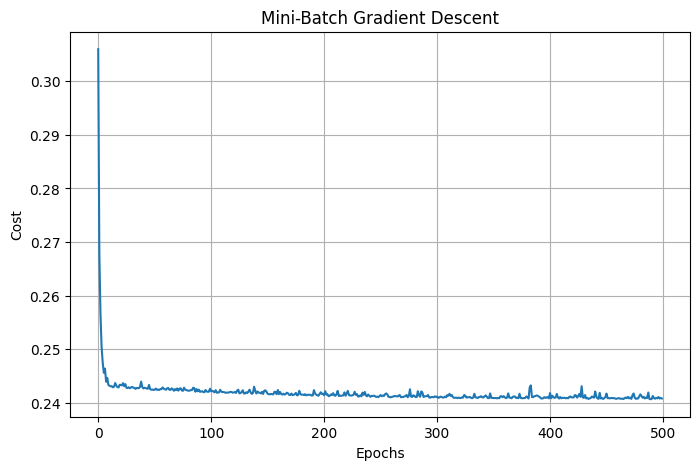

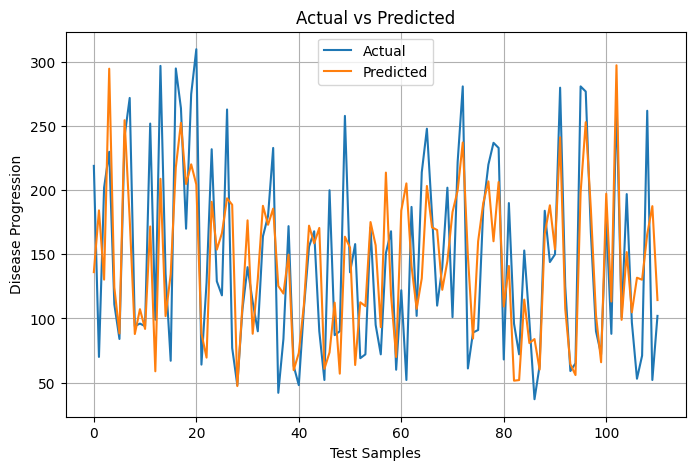

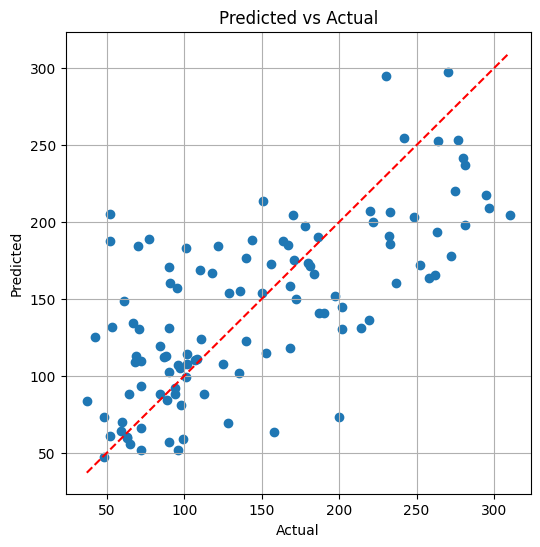

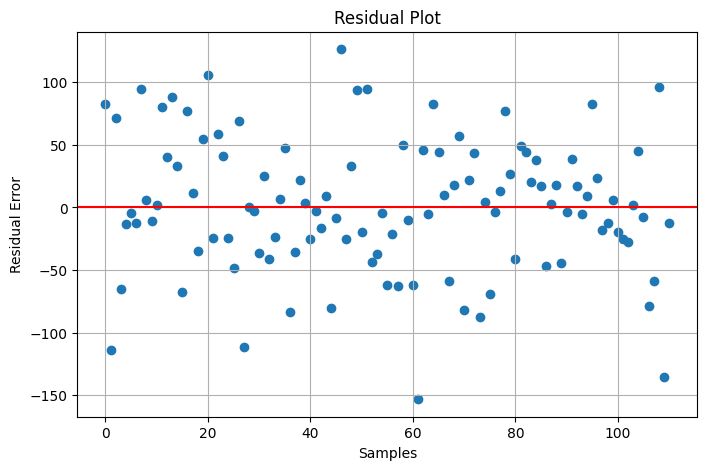

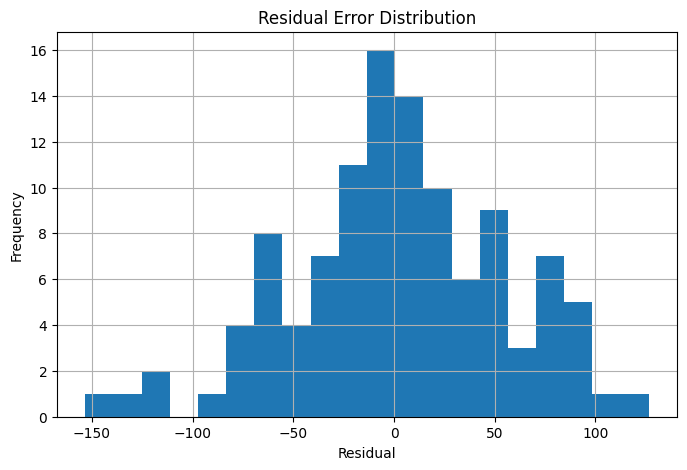

In [ ]:
# Mini-Batch Gradient Descent

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Load predefined dataset
data = load_diabetes()

X = data.data
y = data.target.reshape(-1, 1)

print("Dataset Loaded Successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Normalize features
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Normalize target
y_mean = y_train.mean()
y_std = y_train.std()

y_train = (y_train - y_mean) / y_std

# Add bias column
X_train = np.c_[np.ones((len(X_train), 1)), X_train]
X_test = np.c_[np.ones((len(X_test), 1)), X_test]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# Hypothesis function
def hypothesis(X, theta):
    return X @ theta


# Gradient function
def gradient(X, y, theta):
    error = hypothesis(X, theta) - y
    return (X.T @ error) / len(X)


# Cost function
def cost(X, y, theta):
    error = hypothesis(X, theta) - y
    return np.mean(error ** 2) / 2


# Create Mini-Batches
def create_mini_batches(X, y, batch_size):

    indices = np.random.permutation(len(X))
    mini_batches = []

    for i in range(0, len(X), batch_size):

        batch_indices = indices[i:i + batch_size]

        X_batch = X[batch_indices]
        y_batch = y[batch_indices]

        mini_batches.append((X_batch, y_batch))

    return mini_batches


# Mini-Batch Gradient Descent
def mini_batch_gradient_descent(
    X, y,
    learning_rate=0.03,
    batch_size=32,
    epochs=500
):

    theta = np.zeros((X.shape[1], 1))
    error_list = []

    for epoch in range(epochs):

        batches = create_mini_batches(X, y, batch_size)

        for X_batch, y_batch in batches:

            grad = gradient(X_batch, y_batch, theta)

            theta = theta - learning_rate * grad

        error_list.append(cost(X, y, theta))

    return theta, error_list


# Train model
theta, error_list = mini_batch_gradient_descent(
    X_train, y_train
)

print("\nBias:", theta[0])
print("\nCoefficients:\n", theta[1:])


# Prediction
y_pred = hypothesis(X_test, theta)

# Convert predictions to original scale
y_pred = y_pred * y_std + y_mean


# Performance metrics
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - ss_res / ss_tot

print("\n===== MODEL PERFORMANCE =====")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# Cost vs Epochs
plt.figure(figsize=(8, 5))
plt.plot(error_list)
plt.title("Mini-Batch Gradient Descent")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.grid()
plt.show()


# Actual vs Predicted
plt.figure(figsize=(8, 5))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.title("Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid()
plt.show()


# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual")
plt.grid()
plt.show()


# Residual plot
residual = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(range(len(residual)), residual)
plt.axhline(0, color="red")
plt.title("Residual Plot")
plt.xlabel("Samples")
plt.ylabel("Residual Error")
plt.grid()
plt.show()


# Residual distribution
plt.figure(figsize=(8, 5))
plt.hist(residual, bins=20)
plt.title("Residual Error Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.grid()
plt.show()

Dataset Loaded Successfully!
Features: (442, 10)
Target: (442, 1)
Training Samples: 331
Testing Samples: 111

Bias: [-1.57084107e-16]

Coefficients:
 [[ 0.02923433]
 [-0.14778464]
 [ 0.32511349]
 [ 0.23381755]
 [-0.44187088]
 [ 0.21611052]
 [ 0.01565493]
 [ 0.14978517]
 [ 0.38132514]
 [ 0.01699633]]

===== MODEL PERFORMANCE =====
MAE: 41.512080879464186
MSE: 2844.341858017867
RMSE: 53.33237157691252
R2 Score: 0.48562361326399106


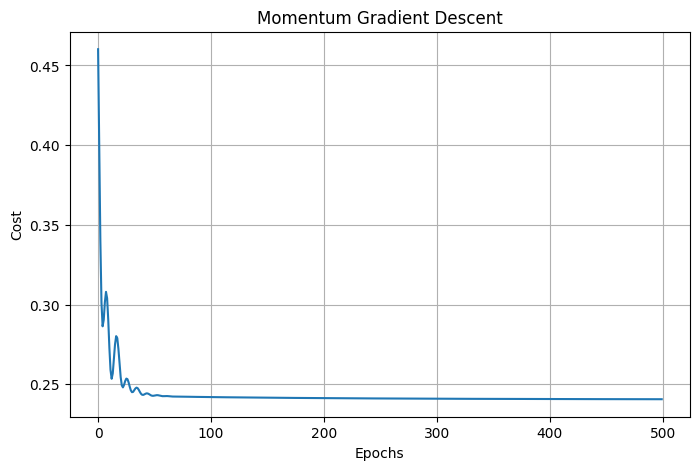

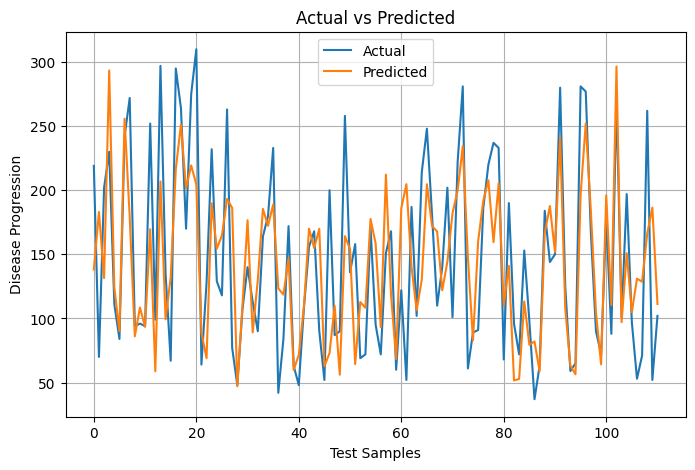

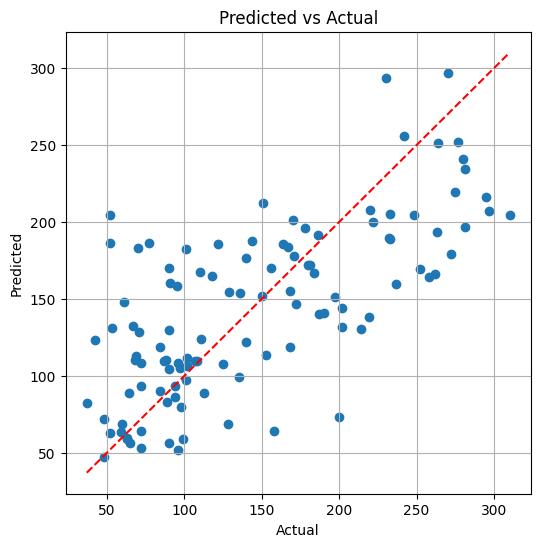

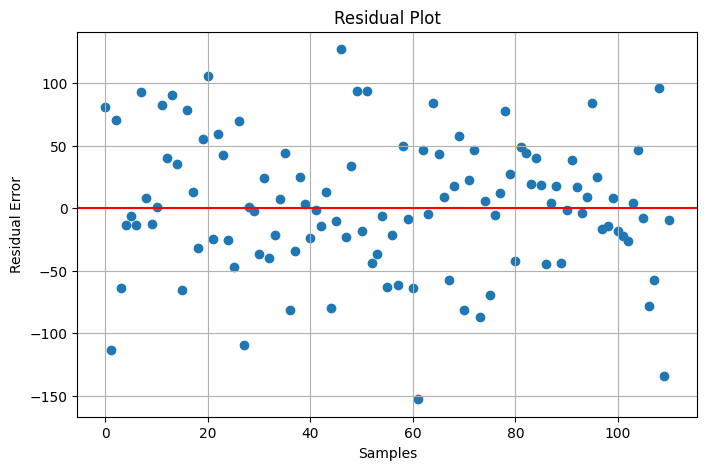

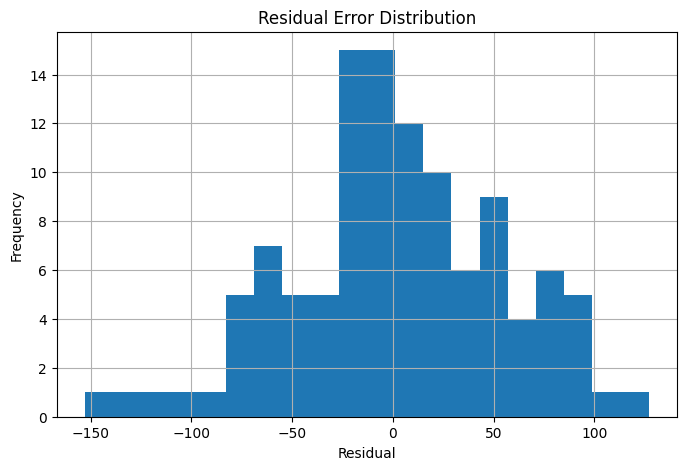

In [ ]:
# Momentum Gradient Descent

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

# Load predefined dataset
data = load_diabetes()

X = data.data
y = data.target.reshape(-1, 1)

print("Dataset Loaded Successfully!")
print("Features:", X.shape)
print("Target:", y.shape)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Normalize features
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# Normalize target
y_mean = y_train.mean()
y_std = y_train.std()

y_train = (y_train - y_mean) / y_std

# Add bias column
X_train = np.c_[np.ones((len(X_train), 1)), X_train]
X_test = np.c_[np.ones((len(X_test), 1)), X_test]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# Hypothesis function
def hypothesis(X, theta):
    return X @ theta


# Gradient function
def gradient(X, y, theta):
    error = hypothesis(X, theta) - y
    return (X.T @ error) / len(X)


# Cost function
def cost(X, y, theta):
    error = hypothesis(X, theta) - y
    return np.mean(error ** 2) / 2


# Momentum Gradient Descent
def momentum_gradient_descent(
    X, y,
    learning_rate=0.03,
    momentum=0.9,
    epochs=500
):

    theta = np.zeros((X.shape[1], 1))
    velocity = np.zeros((X.shape[1], 1))

    error_list = []

    for epoch in range(epochs):

        # Calculate gradient
        grad = gradient(X, y, theta)

        # Update velocity
        velocity = momentum * velocity - learning_rate * grad

        # Update parameters
        theta = theta + velocity

        # Store cost
        error_list.append(cost(X, y, theta))

    return theta, error_list


# Train model
theta, error_list = momentum_gradient_descent(
    X_train, y_train,
    learning_rate=0.03,
    momentum=0.9,
    epochs=500
)

print("\nBias:", theta[0])
print("\nCoefficients:\n", theta[1:])


# Prediction
y_pred = hypothesis(X_test, theta)

# Convert predictions to original scale
y_pred = y_pred * y_std + y_mean


# Performance metrics
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - ss_res / ss_tot

print("\n===== MODEL PERFORMANCE =====")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# Cost vs Epochs
plt.figure(figsize=(8, 5))
plt.plot(error_list)
plt.title("Momentum Gradient Descent")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.grid()
plt.show()


# Actual vs Predicted
plt.figure(figsize=(8, 5))
plt.plot(y_test, label="Actual")
plt.plot(y_pred, label="Predicted")
plt.title("Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid()
plt.show()


# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Predicted vs Actual")
plt.grid()
plt.show()


# Residual plot
residual = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(range(len(residual)), residual)
plt.axhline(0, color="red")
plt.title("Residual Plot")
plt.xlabel("Samples")
plt.ylabel("Residual Error")
plt.grid()
plt.show()


# Residual distribution
plt.figure(figsize=(8, 5))
plt.hist(residual, bins=20)
plt.title("Residual Error Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.grid()
plt.show()